# 2.5 — Route 7 arrival-delay research

**Goal:** clean Route 7 records, place actual and scheduled arrivals side by side, and fit a simple model of arrival delay.

We assume these files are already **in the same folder as this notebook**:

- `RTS_Route7_March2023.xlsx` — recorded bus stop visits.
- `RTS_GTFS_Spring2023.zip` — historical schedule source; leave it zipped.

Run cells in order with **Shift + Enter**. We will work only with **Route 7**. Each stage states what it starts with, what it does, and what it produces. Outputs are dataframes in memory; this notebook does not overwrite source files.

We start with the original **uncleaned** workbook. All cleaning, schedule preparation, and joining happen inside this notebook. There is no prepared CSV to load. The schedule is a separate input because the actual-arrival workbook does not contain published scheduled times.

## Research workflow

| Stage | Question | Output |
| --- | --- | --- |
| 1. Load and inspect | What records do we have? | Original dataframe and data overview. |
| 2. Clean and examine buses | Which records need review, and how are visits organized? | Cleaned copy, flags, and bus-day views. |
| 3. Prepare and link schedules | Which scheduled visit might each actual visit belong to? | Provisional scheduled-versus-actual table. |
| 4. Prepare modeling data | What is the target, what can predict it, and which dates are held out? | Delay target, date split, and encoded predictor tables. |
| 5. Fit and validate regression | Does regression improve on the schedule? | Predictions, validation errors, and plots. |
| 6. Assess and document | Which predictors are justified and what remains uncertain? | Regression diagnostics and research decisions. |

**Suggested stopping points:** finish Stage 3 to review schedule assignments; finish Stage 4 to review predictors before fitting. Stage 6 diagnostics can be covered separately.

**Research status:** time-based schedule assignments are provisional. Results are exploratory research on that linked subset. Verify assignments and assess matching-related selection bias before making claims about overall RTS reliability.

## Stage 1 — Load and inspect the source data

**Input:** original Route 7 Excel workbook.  
**Purpose:** understand rows, columns, coverage, and missing values.  
**Output:** `raw`, an unchanged source dataframe and initial overview.

### 1.1 Import libraries

- `pandas` works with tables.
- `numpy` helps with calculations.
- `matplotlib` makes plots.
- `statsmodels` fits linear regression and provides its diagnostic measures.
- `zipfile` reads the schedule ZIP; it comes with Python.

If a library is missing, install it into your selected Python environment and restart the kernel.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
from IPython.display import display

### 1.2 Load the original Route 7 workbook

This is the same uncleaned file used in Notebook 1. We will modify a dataframe copy, not overwrite your original Excel file.

In [21]:
raw = pd.read_excel("RTS_Route7_March2023.xlsx", engine="openpyxl")
display(raw.head())


,Route,Stop ID,Stop Name,Stop Seq ID,Day of Week,Date,Arrive,Passenger On,Passenger Off,Passenger Load,Passenger Miles,Interstop Distance,Bus,Lat.,Long.
0,7-Downtown Station To Eastwood Meadows,1,Rosa Parks RTS Downtown Station,0,Wednesday,2023-03-01,06:05:27,7,0,7,0.000,0.00,2105,29.64656,-82.32236
1,7-Downtown Station To Eastwood Meadows,292,The Cotton Club,1,Wednesday,2023-03-01,06:06:53,0,0,7,3.873,0.55,2105,29.64581,-82.31482
2,7-Downtown Station To Eastwood Meadows,293,Mt Moriah Baptist Church,2,Wednesday,2023-03-01,06:07:12,0,0,7,1.090,0.16,2105,29.64579,-82.31194
3,7-Downtown Station To Eastwood Meadows,294,Tools for Schools,3,Wednesday,2023-03-01,06:08:46,0,0,7,0.703,0.10,2105,29.64578,-82.30989
4,7-Downtown Station To Eastwood Meadows,295,Williams Elementary School,4,Wednesday,2023-03-01,06:09:00,0,0,7,0.723,0.10,2105,29.64577,-82.30790


### 1.3 Understand the columns and inspect coverage

| Actual-data column | Meaning |
| --- | --- |
| `Bus` | Vehicle ID; one bus can make many journeys. |
| `Date` and `Arrive` | Recorded day and arrival clock time. |
| `Stop ID` | Location label, not the stop's position in the route. |
| `Stop Seq ID` | Position in a recorded stop sequence; can restart. |
| Passenger/distance/location fields | Useful context, but not needed for our first model. |

The schedule has `trip_id` for the scheduled journey, `direction_id`, stop information, and `scheduled_arrival`.

**Discuss:** why could joining only on Stop ID attach many different scheduled times to one observation?

In [22]:
print("Actual-data shape:", raw.shape)
print("Buses:", raw["Bus"].nunique(), "Dates:", raw["Date"].nunique())
display(raw.isna().sum().to_frame("missing_values"))

Actual-data shape: (14685, 15)
Buses: 5 Dates: 17


,missing_values
Route,0
Stop ID,0
Stop Name,0
Stop Seq ID,0
Day of Week,0
Date,0
Arrive,0
Passenger On,0
Passenger Off,0
Passenger Load,0


## Stage 2 — Clean records and examine individual buses

**Input:** `raw`.  
**Purpose:** standardize fields, flag uncertainty, and inspect visits by vehicle/date.  
**Output:** `data`, a working copy with timestamps, source references, and review flags; `bus_summary` and `one_bus_day` for inspection.

### 2.1 Create a working copy and standardize fields

Keep the original unchanged. We add a source-row reference, remove only exact copies of original rows, and create readable column names. Repeated date/bus/stop/time combinations that disagree in other fields are **not** silently collapsed.

Stop IDs become text labels. Dates and times become timestamps so we can subtract them. An invalid clock time becomes missing, rather than being guessed.

In [23]:
data = raw.copy()
data["source_row"] = data.index
data = data.drop_duplicates(subset=raw.columns.tolist()).copy()
data["bus_id"] = data["Bus"].astype("string")
data["stop_id"] = data["Stop ID"].astype("string").str.replace(r"\.0$", "", regex=True)
data["stop_sequence"] = pd.to_numeric(data["Stop Seq ID"], errors="coerce")
data["service_date"] = pd.to_datetime(data["Date"], errors="coerce").dt.normalize()
clock = pd.to_timedelta(data["Arrive"].astype(str), errors="coerce")
clock = clock.where((clock >= pd.Timedelta(0)) & (clock < pd.Timedelta(days=1)))
data["actual_arrival"] = data["service_date"] + clock

print("Rows before:", len(raw), "After exact-copy rule:", len(data))
display(data[["source_row", "bus_id", "stop_id", "stop_sequence", "actual_arrival"]].head())

Rows before: 14685 After exact-copy rule: 14685


,source_row,bus_id,stop_id,stop_sequence,actual_arrival
0,0,2105,1,0,2023-03-01 06:05:27
1,1,2105,292,1,2023-03-01 06:06:53
2,2,2105,293,2,2023-03-01 06:07:12
3,3,2105,294,3,2023-03-01 06:08:46
4,4,2105,295,4,2023-03-01 06:09:00


### 2.2 Flag uncertain observations

We flag missing identifiers/timestamps, unusual sequence/stop codes, conflicting event keys, and tied timestamps within a bus-day. Tied terminal records need separate interpretation; this first exercise leaves them out of automatic matching.

We retain the flags and row counts so we can explain what was excluded.

In [24]:
bad_fields = (
    data[["bus_id", "stop_id", "stop_sequence", "actual_arrival"]].isna().any(axis=1)
    | (data["stop_sequence"] < 0) | (data["stop_sequence"] % 1 != 0)
    | (data["stop_sequence"] == 999) | data["stop_id"].eq("9999").fillna(True)
)
repeated_key = data.duplicated(["bus_id", "service_date", "stop_id", "actual_arrival"], keep=False)
tied_time = data.duplicated(["bus_id", "service_date", "actual_arrival"], keep=False)
data["needs_review"] = bad_fields | repeated_key | tied_time

display(pd.Series({"invalid_fields": int(bad_fields.sum()),
                   "repeated_key_rows": int(repeated_key.sum()),
                   "tied_time_rows": int(tied_time.sum())}).to_frame("flagged_rows"))
display(data.loc[data["needs_review"], ["source_row", "bus_id", "stop_id", "actual_arrival"]].head(6))

,flagged_rows
invalid_fields,126
repeated_key_rows,880
tied_time_rows,907


,source_row,bus_id,stop_id,actual_arrival
31,31,2105,326,2023-03-01 06:31:05
32,32,2105,326,2023-03-01 06:31:05
63,63,2105,1,2023-03-01 06:51:52
64,64,2105,1,2023-03-01 06:51:52
95,95,2105,326,2023-03-01 07:30:20
96,96,2105,327,2023-03-01 07:30:20


### 2.3 Summarize each bus and date

`groupby` summarizes each vehicle/date separately. This does not create a separate model for every bus. The cleaned records will later remain together in one modeling table.

In [25]:
bus_summary = data.groupby(["bus_id", "service_date"]).agg(
    recorded_visits=("source_row", "size"),
    first_arrival=("actual_arrival", "min"),
    last_arrival=("actual_arrival", "max"),
).reset_index()
display(bus_summary.head(10))

,bus_id,service_date,recorded_visits,first_arrival,last_arrival
0,1807,2023-03-14,892,2023-03-14 05:52:03,2023-03-14 19:51:52
1,2005,2023-03-10,830,2023-03-10 07:06:55,2023-03-10 19:52:39
2,2104,2023-03-16,903,2023-03-16 06:01:21,2023-03-16 19:48:46
3,2104,2023-03-21,904,2023-03-21 06:03:01,2023-03-21 19:51:33
4,2104,2023-03-23,717,2023-03-23 06:04:42,2023-03-23 16:58:33
5,2105,2023-03-01,903,2023-03-01 06:05:27,2023-03-01 19:52:05
6,2105,2023-03-02,892,2023-03-02 06:04:00,2023-03-02 19:52:35
7,2105,2023-03-03,641,2023-03-03 06:02:06,2023-03-03 15:54:41
8,2105,2023-03-06,892,2023-03-06 06:01:55,2023-03-06 19:51:41
9,2105,2023-03-07,892,2023-03-07 06:05:22,2023-03-07 19:52:14


### 2.4 Follow one bus through a day

Change the bus/date below to explore another example. Look for repeated stop sequences and possible journey boundaries. This cell is for understanding the data, not assigning ground-truth trip IDs.

In [26]:
bus = "2105"
day = pd.Timestamp("2023-03-01")
one_bus_day = data.loc[(data["bus_id"] == bus) & (data["service_date"] == day)]
one_bus_day = one_bus_day.sort_values(["actual_arrival", "source_row"])
display(one_bus_day[["source_row", "Stop Name", "stop_id", "stop_sequence", "actual_arrival"]].head(40))

,source_row,Stop Name,stop_id,stop_sequence,actual_arrival
0,0,Rosa Parks RTS Downtown Station,1,0,2023-03-01 06:05:27
1,1,The Cotton Club,292,1,2023-03-01 06:06:53
2,2,Mt Moriah Baptist Church,293,2,2023-03-01 06:07:12
3,3,Tools for Schools,294,3,2023-03-01 06:08:46
4,4,Williams Elementary School,295,4,2023-03-01 06:09:00
5,5,Eastbound SE 7th Avenue @ SE 15th Street,297,5,2023-03-01 06:09:15
6,6,Northbound SE 15th Street @ SE 3rd Avenue,96,6,2023-03-01 06:09:51
7,7,Fast Eddies Restaurant,300,7,2023-03-01 06:10:25
8,8,Eastbound University Avenue @ SE 15th Street,301,8,2023-03-01 06:11:05
9,9,Alachua County School Board Administration Annex,303,9,2023-03-01 06:11:25


## Stage 3 — Prepare the historical schedule and propose matches

**Input:** cleaned/flagged actual visits in `data` and the historical GTFS ZIP.  
**Purpose:** attach a plausible scheduled visit without silently accepting ambiguous assignments.  
**Output:** `schedule`, `matched` (provisional links), and `conflict_review` (assignments set aside).

### 3.1 Read the schedule source tables

The workbook has actual arrivals, so we also need RTS's published timetable. GTFS stores that timetable as linked text tables inside a ZIP. We read those tables directly; there is no prepared schedule CSV.

Focus on what each table contributes to the linkage. The helper only reads source tables; it does not clean or approve actual observations.

- `trips`: route, direction, scheduled trip, and service identifiers.
- `stop_times`: ordered stops and published times for each trip.
- `calendar` and `exceptions`: which service runs on a date.
- `stops`: stop names.

Read IDs as text and strip whitespace so joins match correctly.

In [27]:
def read_schedule_table(filename):
    with zipfile.ZipFile("RTS_GTFS_Spring2023.zip") as archive:
        table = pd.read_csv(archive.open(filename), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

trips = read_schedule_table("trips.txt")
stop_times = read_schedule_table("stop_times.txt")
calendar = read_schedule_table("calendar.txt")
exceptions = read_schedule_table("calendar_dates.txt")
stops = read_schedule_table("stops.txt")

route7_trips = trips.loc[trips["route_id"] == "7"]
display(route7_trips[["trip_id", "direction_id", "service_id", "trip_headsign"]].head())

,trip_id,direction_id,service_id,trip_headsign
919,5007001,0,SWB,To Eastwood Meadows
920,5007003,0,SWB,To Eastwood Meadows
921,5007005,0,SWB,To Eastwood Meadows
922,5007007,0,SWB,To Eastwood Meadows
923,5007009,0,SWB,To Eastwood Meadows


### 3.2 Build the date-specific Route 7 timetable

First join scheduled trips to their stop times. Keep only explicit published arrival times; blank intermediate stops must not become invented schedule values.

Then, for each observed date, select the service IDs allowed by the calendar and its date exceptions. Add that date to each scheduled clock time. GTFS can represent times beyond 24:00 for overnight service.

In [ ]:
route7_times = route7_trips.merge(stop_times, on="trip_id", validate="one_to_many")
route7_times = route7_times.loc[route7_times["arrival_time"] != ""].copy()
route7_times = route7_times.merge(stops[["stop_id", "stop_name"]], on="stop_id", validate="many_to_one")

scheduled_days = []
for date in sorted(data["service_date"].dropna().unique()):
    date = pd.Timestamp(date)
    date_code = date.strftime("%Y%m%d")
    active = set(calendar.loc[
        (calendar["start_date"] <= date_code) & (calendar["end_date"] >= date_code)
        & (calendar[date.day_name().lower()] == "1"), "service_id"
    ])

    
    for change in exceptions.loc[exceptions["date"] == date_code].itertuples(index=False):
        if change.exception_type == "1":
            active.add(change.service_id)
        elif change.exception_type == "2":
            active.discard(change.service_id)
    day_schedule = route7_times.loc[route7_times["service_id"].isin(active)].copy()
    day_schedule["service_date"] = date
    day_schedule["scheduled_arrival"] = date + pd.to_timedelta(day_schedule["arrival_time"])
    scheduled_days.append(day_schedule)

schedule = pd.concat(scheduled_days, ignore_index=True)
schedule["stop_sequence"] = pd.to_numeric(schedule["stop_sequence"])
display(schedule[["service_date", "trip_id", "direction_id", "stop_id", "scheduled_arrival"]].head())

,service_date,trip_id,direction_id,stop_id,scheduled_arrival
0,2023-03-01,4059089,0,1,2023-03-01 06:00:00
1,2023-03-01,4059089,0,107,2023-03-01 06:08:00
2,2023-03-01,4059089,0,326,2023-03-01 06:20:00
3,2023-03-01,4059090,0,1,2023-03-01 07:00:00
4,2023-03-01,4059090,0,107,2023-03-01 07:08:00


### 3.3 Check stop order and direction before linking

**First check the schedule pattern.** A location can occur in different directions at different sequence positions. We match both Stop ID and stop order, then use service date and scheduled time to distinguish repeated trips.

This depends on recorded order meaning the same thing as schedule order. Inspect the table below and verify several examples against surrounding stop names before trusting it. Sequence agreement is supporting evidence, not proof of a trip assignment.

In [29]:
pattern_check = schedule[["stop_id", "stop_name", "stop_sequence", "direction_id"]].drop_duplicates()
display(pattern_check.sort_values(["direction_id", "stop_sequence"]))

,stop_id,stop_name,stop_sequence,direction_id
0,1,Rosa Parks RTS Downtown Station,0,0
1,107,Health Department,13,0
2,326,Eastwood Meadows,31,0
42,326,Eastwood Meadows,0,1
43,107,Health Department,18,1
44,1,Rosa Parks RTS Downtown Station,31,1


### 3.4 Generate and filter candidate schedule links

The first merge intentionally creates candidate scheduled visits for each unflagged observation on the same date, stop, and sequence position. There may be several hourly trips.

The initial research linkage rule keeps candidates within **20 minutes** of the recorded arrival. Keep an observation only if exactly one scheduled candidate fits. This does **not** establish correctness: a severely delayed trip could be assigned to the wrong hour, and delays beyond the window are excluded by design.

Do not use the resulting model scores as unbiased evidence of overall schedule reliability. Independent journey review is needed before project conclusions.

In [ ]:
observations = data.loc[~data["needs_review"]].copy()
possible = observations.merge(
    schedule, on=["service_date", "stop_id", "stop_sequence"], how="inner"
)
possible["matching_gap_minutes"] = (
    possible["actual_arrival"] - possible["scheduled_arrival"]
).dt.total_seconds().abs() / 60

MATCH_WINDOW_MINUTES = 20
possible = possible.loc[possible["matching_gap_minutes"] <= MATCH_WINDOW_MINUTES].copy()
possible["candidate_count"] = possible.groupby("source_row")["source_row"].transform("size")
matched = possible.loc[possible["candidate_count"] == 1].copy()

# Two observations must not silently claim the same scheduled stop visit.
conflict = matched.duplicated(["service_date", "trip_id", "stop_sequence"], keep=False)
conflict_review = matched.loc[conflict].copy()
matched = matched.loc[~conflict].copy()
matched["match_status"] = "provisional — requires journey review"

print("Unflagged recorded visits:", len(observations))
print("Visits with one non-conflicting proposed schedule match:", len(matched))
print("Conflicting assignments set aside:", len(conflict_review))
display(matched[["source_row", "bus_id", "stop_id", "direction_id", "trip_id",
                 "scheduled_arrival", "actual_arrival"]].head(10))

                 

Unflagged recorded visits: 13652
Visits with one non-conflicting proposed schedule match: 416
Conflicting assignments set aside: 0


,source_row,bus_id,stop_id,direction_id,trip_id,scheduled_arrival,actual_arrival
0,0,2105,1,0,4059089,2023-03-01 06:00:00,2023-03-01 06:05:27
14,13,2105,107,0,4059089,2023-03-01 06:08:00,2023-03-01 06:13:20
28,50,2105,107,1,4059101,2023-03-01 06:40:00,2023-03-01 06:41:12
43,77,2105,107,0,4059090,2023-03-01 07:08:00,2023-03-01 07:15:59
57,114,2105,107,1,4059102,2023-03-01 07:40:00,2023-03-01 07:40:57
72,141,2105,107,0,4059091,2023-03-01 08:08:00,2023-03-01 08:13:59
86,178,2105,107,1,4059103,2023-03-01 08:40:00,2023-03-01 08:42:34
101,205,2105,107,0,4059092,2023-03-01 09:08:00,2023-03-01 09:11:49
115,242,2105,107,1,4059104,2023-03-01 09:40:00,2023-03-01 09:40:50
130,269,2105,107,0,4059093,2023-03-01 10:08:00,2023-03-01 10:09:53


### 3.5 Review linkage quality before proceeding

Choose at least five examples across buses/dates. Check their source records, neighboring stops, direction, and scheduled journey. Inspect rejected cases too. At terminals, confirm whether the recorded time really means arrival rather than departure.

Only explicit timed stops can match; intermediate stops with no published time remain out of this exercise. Flagged visits and ambiguous/conflicting assignments are also excluded. These choices can bias which service is represented.

The following stages run exploratory analysis on **provisional matches**. Completing five checks is a starting point, not approval of the full dataset. Record your review findings in Stage 6 and revisit the matching rules if the evidence is weak.

**Stage 3 checkpoint:** you should be able to explain exactly how one actual visit received its scheduled trip and why that assignment might be wrong.

## Stage 4 — Define the target, hold out dates, and prepare predictors

**Input:** provisional linked visits in `matched`.  
**Purpose:** define the prediction task and build consistent inputs without using future outcomes as predictors.  
**Output:** `delay_minutes`, `train`, `validation`, `PREDICTORS`, `X_train`, and `X_validation`. Final-test dates remain reserved.

### 4.1 Calculate the target: delay in minutes

**Delay = actual arrival − scheduled arrival.** Positive means late; negative means early. Our model predicts this difference. Trusting the schedule is equivalent to predicting zero delay.

In [31]:
matched["delay_minutes"] = (
    matched["actual_arrival"] - matched["scheduled_arrival"]
).dt.total_seconds() / 60
display(matched[["stop_id", "scheduled_arrival", "actual_arrival", "delay_minutes"]].head())

,stop_id,scheduled_arrival,actual_arrival,delay_minutes
0,1,2023-03-01 06:00:00,2023-03-01 06:05:27,5.450000
14,107,2023-03-01 06:08:00,2023-03-01 06:13:20,5.333333
28,107,2023-03-01 06:40:00,2023-03-01 06:41:12,1.200000
43,107,2023-03-01 07:08:00,2023-03-01 07:15:59,7.983333
57,107,2023-03-01 07:40:00,2023-03-01 07:40:57,0.950000


### 4.2 Reserve chronological training, validation, and test dates

Use Route 7's first 10 observed dates for training, the next 3 for validation, and the last 4 for the final test. Keep whole dates together across all buses. We will not score the final test in this notebook.

Fix this split before choosing features based on their relationship with delay. It does not undo the earlier matching selection bias.

In [32]:
dates = sorted(data["service_date"].dropna().unique())
train = matched.loc[matched["service_date"].isin(dates[:10])].copy()
validation = matched.loc[matched["service_date"].isin(dates[10:13])].copy()

print("Training dates:", pd.to_datetime(dates[:10]).strftime("%m-%d").tolist())
print("Validation dates:", pd.to_datetime(dates[10:13]).strftime("%m-%d").tolist())
print("Reserved test dates:", pd.to_datetime(dates[13:]).strftime("%m-%d").tolist())
print("Training rows:", len(train), "Validation rows:", len(validation))

Training dates: ['03-01', '03-02', '03-03', '03-06', '03-07', '03-08', '03-09', '03-10', '03-13', '03-14']
Validation dates: ['03-15', '03-16', '03-17']
Reserved test dates: ['03-20', '03-21', '03-22', '03-23']
Training rows: 243 Validation rows: 75


### 4.3 Engineer candidate features and justify inclusion/exclusion

| Column | Use and reason |
| --- | --- |
| Stop ID | Category: some locations may have different delays. |
| Direction | Category: outward and return service may differ. |
| Scheduled hour | Number: conditions may change through the day. |
| Weekday | Category: weekdays may differ. |
| Bus, trip, source-row IDs | Keep for tracing records, leave out of this first model. |
| Actual arrival, matching gap, actual delay | Never predictors: they reveal the outcome. |
| Passenger and distance fields | Leave out initially; timing, meaning, and relevance need checking. |

Extract the hour from the **scheduled** arrival, not the target's actual arrival. All initial inputs should be available before the visit happens.

In [33]:
for table in [train, validation]:
    table["scheduled_hour"] = table["scheduled_arrival"].dt.hour
    table["weekday"] = table["service_date"].dt.day_name()

display(train[["stop_id", "direction_id", "scheduled_hour", "weekday", "delay_minutes"]].head())

,stop_id,direction_id,scheduled_hour,weekday,delay_minutes
0,1,0,6,Wednesday,5.450000
14,107,0,6,Wednesday,5.333333
28,107,1,6,Wednesday,1.200000
43,107,0,7,Wednesday,7.983333
57,107,1,7,Wednesday,0.950000


**Feature comparison:** start with stop and direction. Then add scheduled hour and weekday, rerun the remaining cells, and compare validation error. Change one group of features at a time and write down the results.

Previous-stop delay is a possible later feature. It requires a verified preceding visit that would already be known at the forecast moment; do not invent it from the target.

### 4.4 Encode categorical predictors

Regression needs numeric inputs. `get_dummies` creates indicator columns for categories. We drop one reference level to avoid redundant indicators alongside the intercept.

Learn category levels from **training** data, then use those same levels in validation. An unseen validation label is encoded as all-zero indicators (reference-level fallback), which is a limitation printed below. Numeric IDs must not be treated as meaningful magnitudes.

In [34]:
PREDICTORS = ["stop_id", "direction_id", "scheduled_hour", "weekday"]
category_columns = [c for c in PREDICTORS if c in ["stop_id", "direction_id", "weekday"]]

X_train = train[PREDICTORS].copy()
X_validation = validation[PREDICTORS].copy()
for column in category_columns:
    levels = sorted(X_train[column].dropna().unique())
    print("Unseen validation labels in", column, ":", int((~X_validation[column].isin(levels)).sum()))
    X_train[column] = pd.Categorical(X_train[column], categories=levels)
    X_validation[column] = pd.Categorical(X_validation[column], categories=levels)

X_train = pd.get_dummies(X_train, columns=category_columns, drop_first=True, dtype=float)
X_validation = pd.get_dummies(X_validation, columns=category_columns, drop_first=True, dtype=float)
X_validation = X_validation.reindex(columns=X_train.columns, fill_value=0)
X_train = sm.add_constant(X_train.astype(float), has_constant="add")
X_validation = sm.add_constant(X_validation.astype(float), has_constant="add")
display(X_train.head())

Unseen validation labels in stop_id : 0
Unseen validation labels in direction_id : 0
Unseen validation labels in weekday : 0


,const,scheduled_hour,stop_id_107,direction_id_1,weekday_Monday,weekday_Thursday,weekday_Tuesday,weekday_Wednesday
0,1.0,6.0,0.0,0.0,0.0,0.0,0.0,1.0
14,1.0,6.0,1.0,0.0,0.0,0.0,0.0,1.0
28,1.0,6.0,1.0,1.0,0.0,0.0,0.0,1.0
43,1.0,7.0,1.0,0.0,0.0,0.0,0.0,1.0
57,1.0,7.0,1.0,1.0,0.0,0.0,0.0,1.0


## Stage 5 — Fit a regression and evaluate on validation dates

**Input:** encoded predictors and the training/validation delay targets.  
**Purpose:** estimate regression coefficients and compare predictions against simple baselines on later dates.  
**Output:** `model`, `predicted_delay`, the `scores` comparison, an arrival-time example, and a validation plot.

### 5.1 Fit the linear regression using training data only

Ordinary least squares (OLS) is linear regression. It learns an intercept and feature weights from training data. It never fits on the validation rows.

This simple model gives scheduled hour one linear effect. Later we can try time bands or random forest. Negative predicted delay means early arrival and is allowed.

In [35]:
model = sm.OLS(train["delay_minutes"], X_train).fit()
predicted_delay = model.predict(X_validation)
display(model.params.rename("coefficient_in_minutes").to_frame())

,coefficient_in_minutes
const,6.068169
scheduled_hour,-0.121973
stop_id_107,0.307872
direction_id_1,-2.793887
weekday_Monday,-0.895482
weekday_Thursday,-0.507471
weekday_Tuesday,-1.193796
weekday_Wednesday,-0.353471


### 5.2 Compare validation errors with schedule and mean baselines

**MAE** is the average absolute error in minutes; lower is better. **RMSE** emphasizes large mistakes. **Validation R²** compares squared error with predicting the validation mean; it can be negative.

The published-schedule baseline predicts zero delay. We also show a simple training-mean-delay baseline. All methods are evaluated on the **same validation rows**.

These are exploratory scores on provisionally matched records. Their interpretation depends on schedule-linkage quality and the subset selected by our rules.

In [36]:
actual = validation["delay_minutes"]
predictions = {
    "Published schedule": np.zeros(len(validation)),
    "Training mean delay": np.repeat(train["delay_minutes"].mean(), len(validation)),
    "Linear regression": predicted_delay.to_numpy(),
}
scores = []
for name, predicted in predictions.items():
    errors = actual.to_numpy() - predicted
    total_variation = ((actual - actual.mean()) ** 2).sum()
    scores.append({"method": name, "MAE_minutes": np.abs(errors).mean(),
        "RMSE_minutes": np.sqrt((errors ** 2).mean()),
        "validation_R2": 1 - (errors ** 2).sum() / total_variation if total_variation > 0 else np.nan,
        "rows": len(actual)})
print("EXPLORATORY RESEARCH — provisional schedule matches")
display(pd.DataFrame(scores).round(3))

EXPLORATORY RESEARCH — provisional schedule matches


,method,MAE_minutes,RMSE_minutes,validation_R2,rows
0,Published schedule,2.867,3.830,-0.960,75
1,Training mean delay,1.847,2.759,-0.017,75
2,Linear regression,2.125,2.678,0.042,75


### 5.3 Convert predicted delay into an arrival timestamp

**Predicted arrival = scheduled arrival + predicted delay.** This is a historical replay, not live bus tracking.

In [37]:
example = validation[["bus_id", "stop_id", "scheduled_arrival", "actual_arrival"]].copy()
example["predicted_delay_minutes"] = predicted_delay
example["predicted_arrival"] = example["scheduled_arrival"] + pd.to_timedelta(predicted_delay, unit="min")
display(example.head(6))

,bus_id,stop_id,scheduled_arrival,actual_arrival,predicted_delay_minutes,predicted_arrival
3402,2107,1,2023-03-15 06:00:00,2023-03-15 06:07:44,4.982859,2023-03-15 06:04:58.971555804
3416,2107,107,2023-03-15 06:08:00,2023-03-15 06:16:06,5.290732,2023-03-15 06:13:17.443895784
3430,2107,107,2023-03-15 06:40:00,2023-03-15 06:45:06,2.496845,2023-03-15 06:42:29.810684646
3445,2107,107,2023-03-15 07:08:00,2023-03-15 07:11:24,5.168759,2023-03-15 07:13:10.125513048
3459,2107,107,2023-03-15 07:40:00,2023-03-15 07:43:30,2.374872,2023-03-15 07:42:22.492301910
3474,2107,107,2023-03-15 08:08:00,2023-03-15 08:10:09,5.046786,2023-03-15 08:13:02.807130312


### 5.4 Inspect the validation-error plot

Points near the diagonal are good predictions. Which examples are far away? Could those be real delays, poor predictions, or wrong schedule matches?

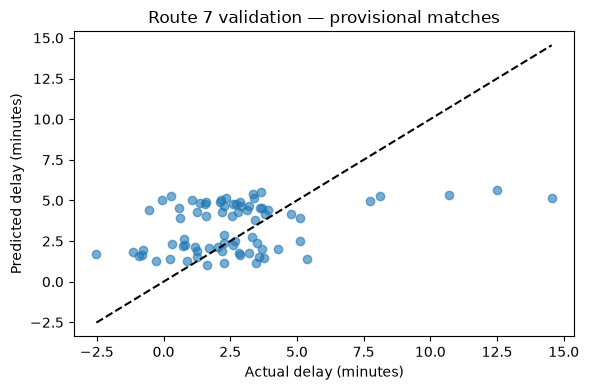

In [38]:
plt.figure(figsize=(6, 4))
plt.scatter(actual, predicted_delay, alpha=0.6)
low = min(actual.min(), predicted_delay.min())
high = max(actual.max(), predicted_delay.max())
plt.plot([low, high], [low, high], "k--")
plt.xlabel("Actual delay (minutes)")
plt.ylabel("Predicted delay (minutes)")
plt.title("Route 7 validation — provisional matches")
plt.tight_layout()
plt.show()

## Stage 6 — Assess predictors and document research decisions

**Input:** fitted regression, training design matrix, and validation results.  
**Purpose:** investigate fit, complexity, and redundant predictors, then explain the scope of conclusions.  
**Output:** regression diagnostics, VIF results where applicable, and written research decisions.

### 6.1 Optional regression diagnostics

The first model is complete. Use this section only if there is time.

| Measure | What it helps us ask |
| --- | --- |
| Validation MAE / R² | Does the model predict later observations well? |
| Training adjusted R² | How does training fit change after accounting for predictor count? |
| Training AIC / BIC | Is a suitable regression specification's fit worth its complexity? Compare on the same target and training rows. |
| VIF | Are encoded predictors redundant? |

AIC/BIC do not compare this model with random forest. For different model families, use the same validation dates and error measures. Do not choose features from final-test results.

In [39]:
display(pd.Series({
    "training_R2": model.rsquared,
    "training_adjusted_R2": model.rsquared_adj,
    "training_AIC": model.aic,
    "training_BIC": model.bic,
}).to_frame("regression_diagnostic"))

print("Encoded columns:", X_train.shape[1], "Design rank:", np.linalg.matrix_rank(X_train))

,regression_diagnostic
training_R2,0.309816
training_adjusted_R2,0.289257
training_AIC,1105.441815
training_BIC,1133.386306


Encoded columns: 8 Design rank: 8


### 6.2 Optional collinearity assessment using VIF

VIF includes the intercept when calculating redundancy, but we report only predictor VIFs. If the design rank is smaller than its column count, simplify the redundant inputs first.

Use these measures for discussion, not as automatic deletion rules. Stop visits are correlated within buses/journeys/dates, so standard OLS p-values are not reliable evidence of independent or causal effects.

In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

if np.linalg.matrix_rank(X_train) < X_train.shape[1]:
    print("Redundant columns: review the chosen predictors before interpreting coefficients or VIF.")
else:
    vif = pd.DataFrame({
        "encoded_predictor": X_train.columns[1:],
        "VIF": [variance_inflation_factor(X_train.to_numpy(), i) for i in range(1, X_train.shape[1])],
    })
    display(vif)

,encoded_predictor,VIF
0,scheduled_hour,1.116247
1,stop_id_107,1.148767
2,direction_id_1,1.030807
3,weekday_Monday,1.671017
4,weekday_Thursday,1.680171
5,weekday_Tuesday,1.671488
6,weekday_Wednesday,1.680171


### 6.3 Record the research decisions and limitations

Edit this cell with your group's answers:

1. **A cleaning decision and its justification:**
2. **One proposed schedule match we checked, and evidence for/against it:**
3. **Which observations our matching rules exclude and how that can bias results:**
4. **Why each chosen predictor would be known before arrival:**
5. **Whether regression beat the schedule on validation MAE:**
6. **What changed when we removed/added scheduled hour or weekday:**
7. **What must be verified before treating these results as project findings:**

Save your notebook. It does not change either input file or write any extra files.

Next research step: improve schedule-match verification and compare random forest using the same Route 7 rows and dates. Keep the final-test dates reserved. We are not adding other routes in this workbook.

**Data sources:** Route 7 ride-check data deposited by Richard Borzi, University of Florida, supplied by Gainesville RTS; [Zenodo](https://zenodo.org/records/10034933), CC BY 4.0. Schedule read directly from [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0), using service calendars and exceptions for the dates in the actual workbook. Neither current schedules nor interpolated intermediate times were substituted.